# Entrenamiento

In [15]:
"""
ENTRENAMIENTO DEL MODELO PREDICTIVO DE LPIPS
================================================================================
Implementa el protocolo descrito: compara experimentalmente el Modelo A
(MLP base: 64, 32) y el Modelo B (MLP propuesto: 128, 64, 32), cada uno
bajo las tres funciones de perdida candidatas (MSE, MAE, Huber), con el
mismo optimizador (Adam), misma particion train/val/test y mismo criterio
de parada temprana. Las metricas de seleccion (MAE, RMSE, R2) se calculan
sobre el conjunto de VALIDACION. El conjunto de PRUEBA se evalua una sola
vez, al final, unicamente sobre la configuracion ganadora.
 
Requiere los archivos generados en la etapa de separacion y normalizacion:
  csv/X_train.csv, csv/X_val.csv, csv/X_test.csv
  csv/y_train.csv, csv/y_val.csv, csv/y_test.csv
"""
 
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
from pathlib import Path

CARPETA_GRAFICAS = Path("graficas_entrenamiento")
CARPETA_GRAFICAS.mkdir(parents=True, exist_ok=True)
 
tf.random.set_seed(42)
np.random.seed(42)
 

# ------------------------------------------------------------------
# 0. CARGA DE DATOS (ya separados y normalizados en la etapa anterior)
# ------------------------------------------------------------------

In [16]:
X_train = pd.read_csv("csv/X_train.csv")
X_val = pd.read_csv("csv/X_val.csv")
X_test = pd.read_csv("csv/X_test.csv")
y_train = pd.read_csv("csv/y_train.csv").squeeze()
y_val = pd.read_csv("csv/y_val.csv").squeeze()
y_test = pd.read_csv("csv/y_test.csv").squeeze()
 
n_features = X_train.shape[1]
print(f"Dimension de entrada: {n_features} caracteristicas "
      f"(train={len(X_train)}, val={len(X_val)}, test={len(X_test)})")

Dimension de entrada: 32 caracteristicas (train=20990, val=4498, test=4499)


# ------------------------------------------------------------------
# 1. FUNCION PARA CONSTRUIR EL MLP (arquitectura parametrizable)
# ------------------------------------------------------------------

In [17]:
def construir_mlp(capas_ocultas, n_features, dropout_rate=0.2,
                   activacion_salida="linear"):
    """
    Construye un MLP de regresion con las capas ocultas indicadas.
    capas_ocultas: lista con el numero de neuronas de cada capa oculta,
                   p. ej. [64, 32] para el Modelo A o [128, 64, 32] para
                   el Modelo B.
    """
    modelo = keras.Sequential(name=f"MLP_{'_'.join(map(str, capas_ocultas))}")
    modelo.add(layers.Input(shape=(n_features,)))
    for n_neuronas in capas_ocultas:
        modelo.add(layers.Dense(n_neuronas, activation="relu"))
        modelo.add(layers.Dropout(dropout_rate))
    modelo.add(layers.Dense(1, activation=activacion_salida))
    return modelo

# ------------------------------------------------------------------
# 2. PROTOCOLO DE ENTRENAMIENTO COMUN
# ------------------------------------------------------------------

In [31]:
def entrenar_y_evaluar(
    capas_ocultas,
    nombre_modelo,
    funcion_perdida,
    nombre_perdida,
    dropout_rate=0.2,
    epochs=200,
    batch_size=64
):
    modelo = construir_mlp(capas_ocultas, n_features, dropout_rate)

    modelo.compile(
        optimizer=keras.optimizers.Adam(),
        loss=funcion_perdida,
        metrics=["mae"],
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )

    historial = modelo.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0,
    )

    # Evaluación sobre validación
    y_pred_val = modelo.predict(X_val, verbose=0).flatten()

    mae = mean_absolute_error(y_val, y_pred_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    r2 = r2_score(y_val, y_pred_val)

    # Análisis de predicciones negativas
    negativas = y_pred_val < 0
    n_negativas = negativas.sum()
    pct_negativas = n_negativas / len(y_pred_val) * 100

    magnitud_media_negativas = (
        y_pred_val[negativas].mean()
        if n_negativas > 0 else 0.0
    )

    resultado = {
        "modelo": nombre_modelo,
        "arquitectura": "-".join(map(str, capas_ocultas)),
        "funcion_perdida": nombre_perdida,
        "epocas_entrenadas": len(historial.history["loss"]),
        "val_MAE": mae,
        "val_RMSE": rmse,
        "val_R2": r2,
        "pred_negativas_n": n_negativas,
        "pred_negativas_%": pct_negativas,
        "pred_negativas_magnitud_media": magnitud_media_negativas,
    }

    return modelo, resultado, historial.history


# ------------------------------------------------------------------
# 3. COMPARACION EXPERIMENTAL: Modelo A vs. Modelo B x {MSE, MAE, Huber}
# ------------------------------------------------------------------

In [32]:
historiales = {}

configuraciones = {
    "Modelo A (64-32)": [64, 32],
    "Modelo B (128-64-32)": [128, 64, 32],
}

funciones_perdida = {
    "mse": "mse",
    "mae": "mae",
    "huber": keras.losses.Huber(),
}

resultados = []
modelos_entrenados = {}

print("\n" + "=" * 70)
print("COMPARACION EXPERIMENTAL DE ARQUITECTURAS Y FUNCIONES DE PERDIDA")
print("=" * 70)

for nombre_cfg, capas in configuraciones.items():
    for nombre_perdida, perdida in funciones_perdida.items():

        clave = f"{nombre_cfg} | {nombre_perdida}"
        print(f"\nEntrenando: {clave} ...")

        modelo, resultado, historial = entrenar_y_evaluar(
            capas_ocultas=capas,
            nombre_modelo=nombre_cfg,
            funcion_perdida=perdida,
            nombre_perdida=nombre_perdida,
            dropout_rate=0.2
        )

        historiales[clave] = historial
        modelos_entrenados[clave] = modelo
        resultados.append(resultado)

        print(
            f"  -> val_MAE={resultado['val_MAE']:.5f}  "
            f"val_RMSE={resultado['val_RMSE']:.5f}  "
            f"val_R2={resultado['val_R2']:.4f}  "
            f"pred_negativas={resultado['pred_negativas_%']:.2f}%"
        )

tabla_resultados = (
    pd.DataFrame(resultados)
    .sort_values("val_MAE")
)

print("\n" + "=" * 70)
print("TABLA COMPARATIVA (ordenada por val_MAE)")
print("=" * 70)

print(tabla_resultados.to_string(index=False))

tabla_resultados.to_csv(
    "csv/comparacion_modelos.csv",
    index=False
)

print("\nGuardado: csv/comparacion_modelos.csv")


COMPARACION EXPERIMENTAL DE ARQUITECTURAS Y FUNCIONES DE PERDIDA

Entrenando: Modelo A (64-32) | mse ...
  -> val_MAE=0.01327  val_RMSE=0.02209  val_R2=0.9387  pred_negativas=0.29%

Entrenando: Modelo A (64-32) | mae ...
  -> val_MAE=0.01105  val_RMSE=0.02230  val_R2=0.9375  pred_negativas=24.37%

Entrenando: Modelo A (64-32) | huber ...
  -> val_MAE=0.01298  val_RMSE=0.02175  val_R2=0.9406  pred_negativas=0.18%

Entrenando: Modelo B (128-64-32) | mse ...
  -> val_MAE=0.01273  val_RMSE=0.02240  val_R2=0.9370  pred_negativas=0.36%

Entrenando: Modelo B (128-64-32) | mae ...
  -> val_MAE=0.01048  val_RMSE=0.02116  val_R2=0.9438  pred_negativas=0.00%

Entrenando: Modelo B (128-64-32) | huber ...
  -> val_MAE=0.01199  val_RMSE=0.02159  val_R2=0.9415  pred_negativas=0.56%

TABLA COMPARATIVA (ordenada por val_MAE)
              modelo arquitectura funcion_perdida  epocas_entrenadas  val_MAE  val_RMSE   val_R2  pred_negativas_n  pred_negativas_%  pred_negativas_magnitud_media
Modelo B (128-6

# ------------------------------------------------------------------
# 4. SELECCION DE LA CONFIGURACION GANADORA (menor val_MAE)
# ------------------------------------------------------------------

In [35]:
mejor_fila = tabla_resultados.iloc[0]
mejor_clave = f"{mejor_fila['modelo']} | " \
              f"{[k for k, v in funciones_perdida.items() if (isinstance(v, str) and v == mejor_fila['funcion_perdida']) or (not isinstance(v, str) and mejor_fila['funcion_perdida'] not in funciones_perdida)][0] if isinstance(mejor_fila['funcion_perdida'], str) else 'huber'}"
 
# Forma robusta de recuperar la clave exacta usada en modelos_entrenados:
mejor_clave = [
    k for k in modelos_entrenados.keys()
    if k.startswith(mejor_fila["modelo"]) and (
        (mejor_fila["funcion_perdida"] in ("mse", "mae") and k.endswith(mejor_fila["funcion_perdida"]))
        or (mejor_fila["funcion_perdida"] not in ("mse", "mae") and k.endswith("huber"))
    )
][0]
 
modelo_final = modelos_entrenados[mejor_clave]
print(f"\nConfiguracion seleccionada: {mejor_clave}")
print(f"val_MAE={mejor_fila['val_MAE']:.5f}  val_RMSE={mejor_fila['val_RMSE']:.5f}  "
      f"val_R2={mejor_fila['val_R2']:.4f}")


Configuracion seleccionada: Modelo B (128-64-32) | mae
val_MAE=0.01048  val_RMSE=0.02116  val_R2=0.9438


# ------------------------------------------------------------------
# 5. EVALUACION FINAL UNICA SOBRE EL CONJUNTO DE PRUEBA
#    (no se utiliza para seleccionar arquitectura ni ajustar hiperparametros)
# ------------------------------------------------------------------

In [36]:
y_pred_test = modelo_final.predict(X_test, verbose=0).flatten()
mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)
n_neg_test = (y_pred_test < 0).sum()
 
print("\n" + "=" * 70)
print("EVALUACION FINAL SOBRE EL CONJUNTO DE PRUEBA (unica evaluacion)")
print("=" * 70)
print(f"test_MAE  = {mae_test:.5f}")
print(f"test_RMSE = {rmse_test:.5f}")
print(f"test_R2   = {r2_test:.4f}")
print(f"Predicciones negativas en test: {n_neg_test} "
      f"({n_neg_test/len(y_pred_test)*100:.2f}%)")


EVALUACION FINAL SOBRE EL CONJUNTO DE PRUEBA (unica evaluacion)
test_MAE  = 0.01043
test_RMSE = 0.02084
test_R2   = 0.9476
Predicciones negativas en test: 0 (0.00%)


# ------------------------------------------------------------------
# 6. GUARDAR EL MODELO FINAL
# ------------------------------------------------------------------

In [37]:
modelo_final.save("modelo_lpips_final.keras")
print("\nModelo final guardado: modelo_lpips_final.keras")


Modelo final guardado: modelo_lpips_final.keras


# ==============================================================
# 7. GRAFICAS COMPARATIVAS DE LOS SEIS EXPERIMENTOS
# ==============================================================

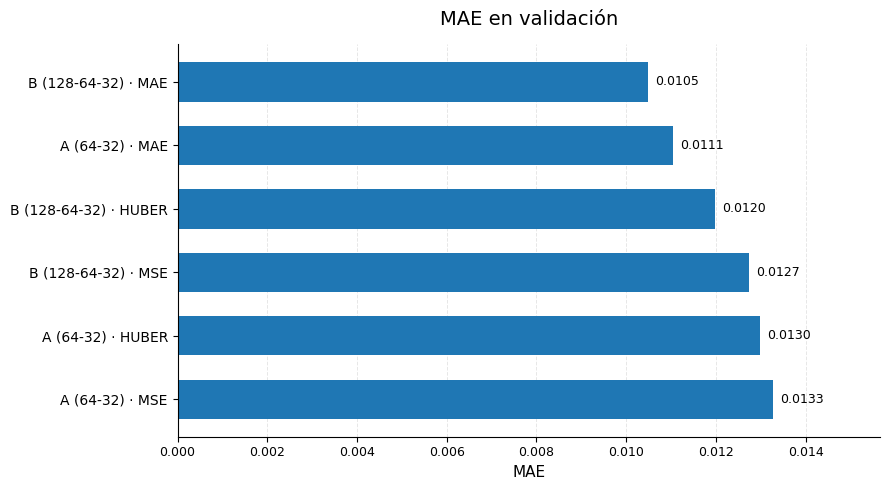

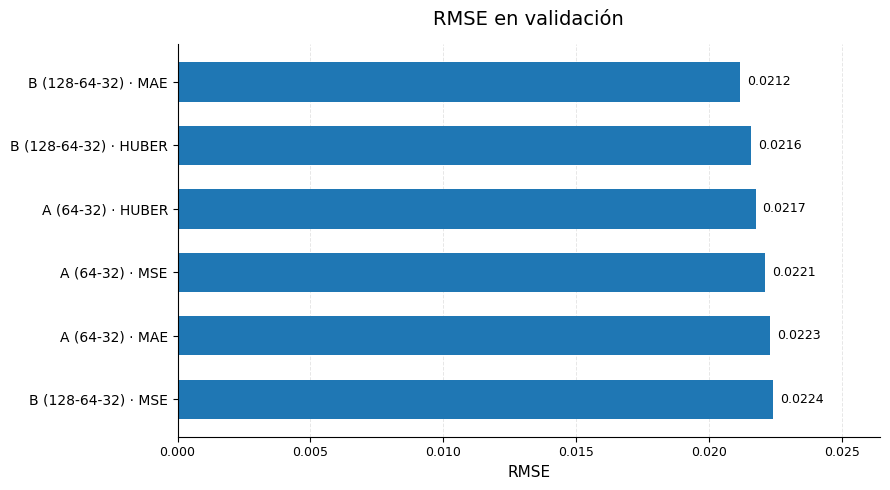

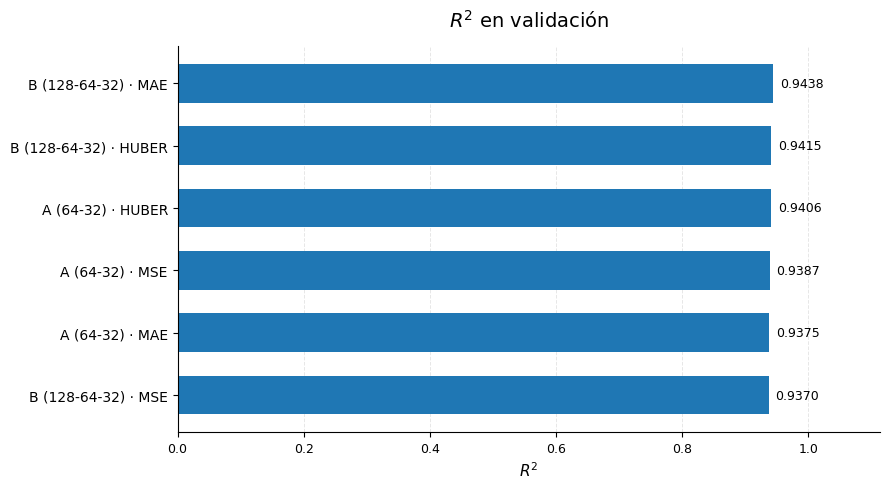

Gráficas guardadas en: D:\TrabajoGrado\Codigos\Funciones_Matematicas\graficas_modelo


In [38]:

# ==============================================================
# GRAFICAS COMPARATIVAS DE LOS SEIS EXPERIMENTOS
# ==============================================================

import matplotlib.pyplot as plt
from pathlib import Path

CARPETA_GRAFICAS = Path("graficas_modelo")
CARPETA_GRAFICAS.mkdir(parents=True, exist_ok=True)

# Etiquetas breves y consistentes
df_graficas = tabla_resultados.copy()

df_graficas["configuracion"] = (
    df_graficas["modelo"]
    .str.replace("Modelo A (64-32)", "A (64-32)", regex=False)
    .str.replace("Modelo B (128-64-32)", "B (128-64-32)", regex=False)
    + " · "
    + df_graficas["funcion_perdida"].astype(str).str.upper()
)

metricas = [
    ("val_MAE", "MAE en validación", "MAE", "comparacion_mae.png", True),
    ("val_RMSE", "RMSE en validación", "RMSE", "comparacion_rmse.png", True),
    ("val_R2", r"$R^2$ en validación", r"$R^2$", "comparacion_r2.png", False),
]

for columna, titulo, etiqueta_x, archivo, ascendente in metricas:

    datos = df_graficas.sort_values(
        columna, ascending=ascendente
    ).dropna(subset=[columna])

    fig, ax = plt.subplots(figsize=(9, 5))

    barras = ax.barh(
        datos["configuracion"],
        datos[columna],
        height=0.62
    )

    ax.set_title(titulo, fontsize=14, pad=14)
    ax.set_xlabel(etiqueta_x, fontsize=11)
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=10)
    ax.tick_params(axis="x", labelsize=9)

    # Colocar el mejor resultado arriba
    ax.invert_yaxis()

    # Cuadrícula discreta
    ax.grid(axis="x", linestyle="--", linewidth=0.7, alpha=0.3)
    ax.set_axisbelow(True)

    # Valores al final de cada barra
    ax.bar_label(
        barras,
        labels=[f"{v:.4f}" for v in datos[columna]],
        padding=5,
        fontsize=9
    )

    # Espacio para que los valores no queden fuera de la figura
    minimo = min(0, datos[columna].min())
    maximo = datos[columna].max()
    margen = (maximo - minimo) * 0.18

    if margen == 0:
        margen = max(abs(maximo) * 0.05, 0.01)

    ax.set_xlim(minimo, maximo + margen)

    # Quitar bordes visuales innecesarios
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()
    fig.savefig(
        CARPETA_GRAFICAS / archivo,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close(fig)

print(f"Gráficas guardadas en: {CARPETA_GRAFICAS.resolve()}")

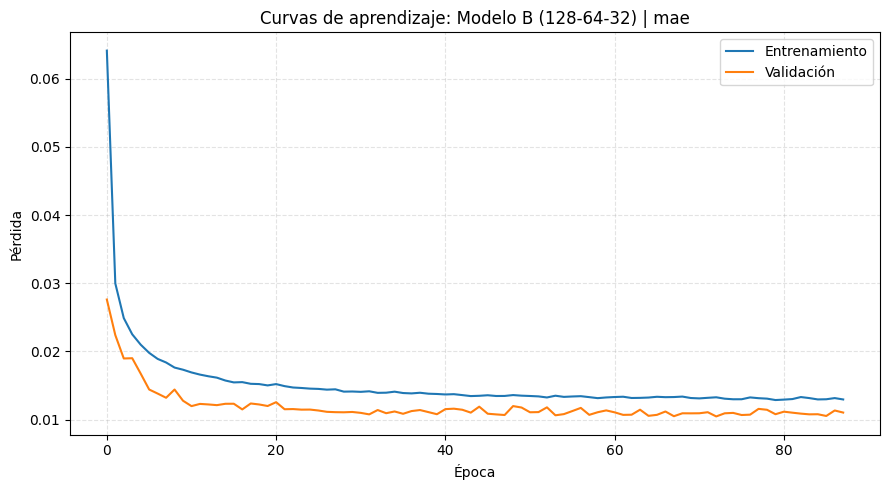

In [39]:

# ==============================================================
# 8. CURVAS DE APRENDIZAJE DEL MODELO SELECCIONADO
# ==============================================================

historial_ganador = historiales[mejor_clave]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    historial_ganador["loss"],
    label="Entrenamiento"
)
ax.plot(
    historial_ganador["val_loss"],
    label="Validación"
)

ax.set_title(f"Curvas de aprendizaje: {mejor_clave}")
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.35)

fig.tight_layout()
fig.savefig(
    CARPETA_GRAFICAS / "curvas_aprendizaje.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

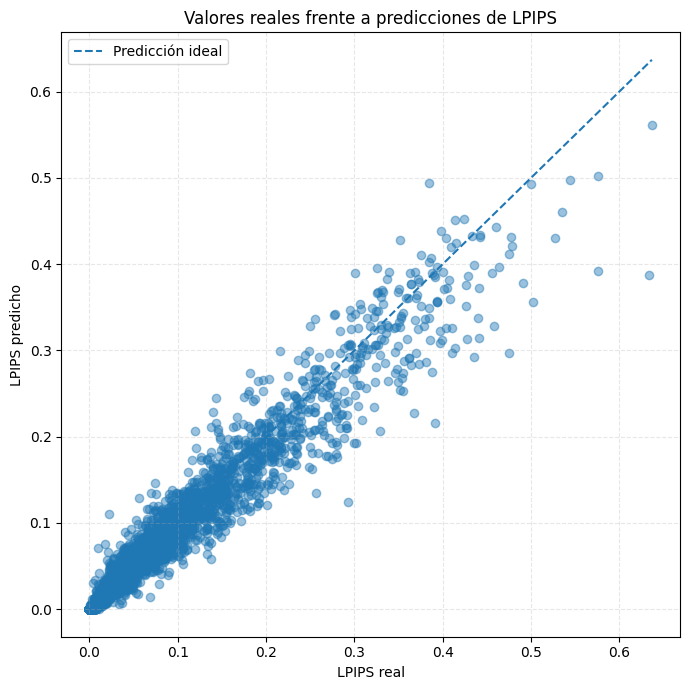

In [41]:

# ==============================================================
# 9. VALORES REALES FRENTE A PREDICCIONES EN TEST
# ==============================================================

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(y_test, y_pred_test, alpha=0.45)

limite_min = min(float(np.min(y_test)), float(np.min(y_pred_test)))
limite_max = max(float(np.max(y_test)), float(np.max(y_pred_test)))

ax.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--",
    label="Predicción ideal"
)

ax.set_title("Valores reales frente a predicciones de LPIPS")
ax.set_xlabel("LPIPS real")
ax.set_ylabel("LPIPS predicho")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

fig.tight_layout()
fig.savefig(
    CARPETA_GRAFICAS / "reales_vs_predichos_test.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)